# 1. Import Libraries

In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# 2. Load Dataset dan EDA

### 2.1 Load dan lihat isi dataset

In [120]:
df = pd.read_csv('Transactions_Dataset.csv')
df.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


### 2.2 Informasi dataset (shape, info, describe)

In [121]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Transaction_ID                    51000 non-null  object 
 1   User_ID                           51000 non-null  int64  
 2   Transaction_Amount                48480 non-null  float64
 3   Transaction_Type                  51000 non-null  object 
 4   Time_of_Transaction               48448 non-null  float64
 5   Device_Used                       48527 non-null  object 
 6   Location                          48453 non-null  object 
 7   Previous_Fraudulent_Transactions  51000 non-null  int64  
 8   Account_Age                       51000 non-null  int64  
 9   Number_of_Transactions_Last_24H   51000 non-null  int64  
 10  Payment_Method                    48531 non-null  object 
 11  Fraudulent                        51000 non-null  int64  
dtypes: f

In [122]:
df.describe()

,User_ID,Transaction_Amount,Time_of_Transaction,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Fraudulent
count,51000.000000,48480.000000,48448.000000,51000.000000,51000.000000,51000.000000,51000.000000
mean,3005.110176,2996.249784,11.488400,1.995725,60.033902,7.495588,0.049216
std,1153.121107,5043.932555,6.922954,1.415150,34.384131,4.020080,0.216320
min,1000.000000,5.030000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,2007.000000,1270.552500,5.000000,1.000000,30.000000,4.000000,0.000000
50%,2996.000000,2524.100000,12.000000,2.000000,60.000000,7.000000,0.000000
75%,4006.000000,3787.240000,17.000000,3.000000,90.000000,11.000000,0.000000
max,4999.000000,49997.800000,23.000000,4.000000,119.000000,14.000000,1.000000


### 2.3 Distribusi target (Fraudulent)

Non-Fraud (0): 48490 (95.08%)
Fraud (1): 2510 (4.92%)


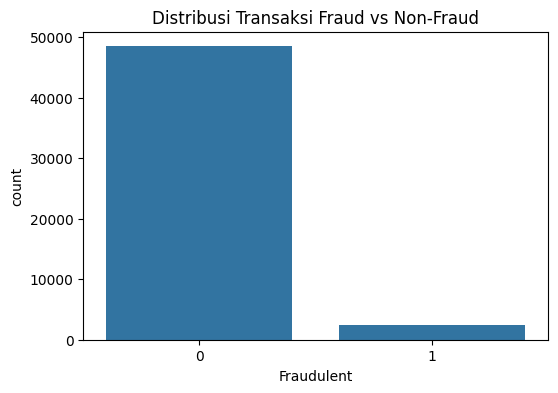

In [123]:
fraud_count = df['Fraudulent'].value_counts()
fraud_percent = df['Fraudulent'].value_counts(normalize=True) * 100
print(f"Non-Fraud (0): {fraud_count[0]} ({fraud_percent[0]:.2f}%)")
print(f"Fraud (1): {fraud_count[1]} ({fraud_percent[1]:.2f}%)")

plt.figure(figsize=(6,4))
sns.countplot(x='Fraudulent', data=df)
plt.title('Distribusi Transaksi Fraud vs Non-Fraud')
plt.show()

### 2.4 Cross Tabulation (Transaction_Type vs Fraudulent)

In [124]:
pd.crosstab(df['Transaction_Type'], df['Fraudulent'], normalize='index')

Fraudulent,0,1
Transaction_Type,,
ATM Withdrawal,0.953463,0.046537
Bank Transfer,0.951927,0.048073
Bill Payment,0.950484,0.049516
Online Purchase,0.948088,0.051912
POS Payment,0.949931,0.050069


### 2.5 Korelasi Heatmap

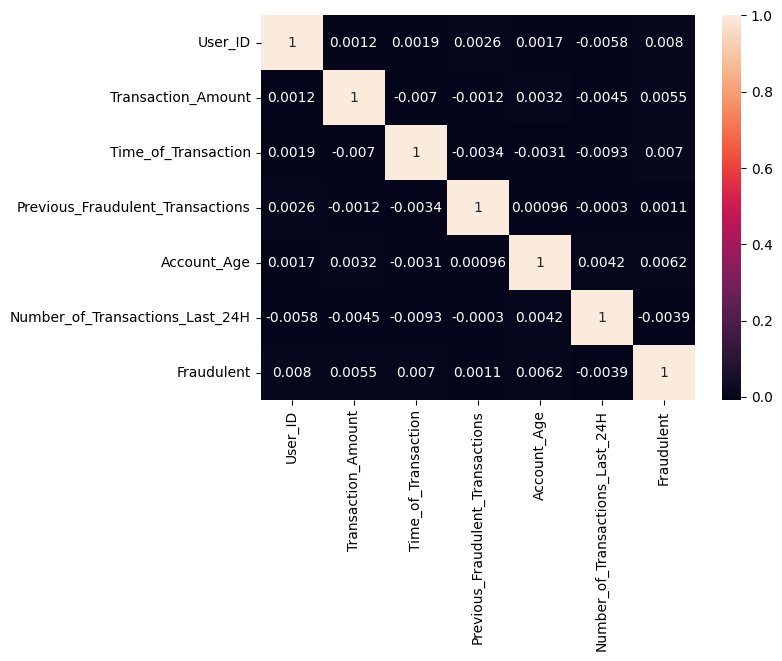

In [125]:
all_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_cols = [col for col in all_cols if col != 'Fraudulent']

plt.figure(figsize=(7,5))
sns.heatmap(df[numeric_cols + ['Fraudulent']].corr(), annot=True)
plt.show()

### 2.6 Boxplot

Kolom yang dicek outliernya: ['User_ID', 'Transaction_Amount', 'Time_of_Transaction', 'Previous_Fraudulent_Transactions', 'Account_Age', 'Number_of_Transactions_Last_24H']


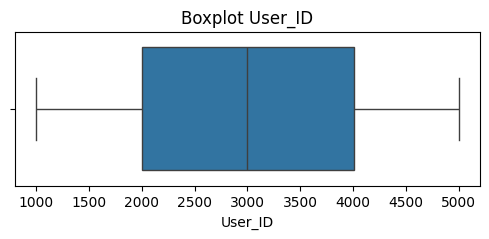

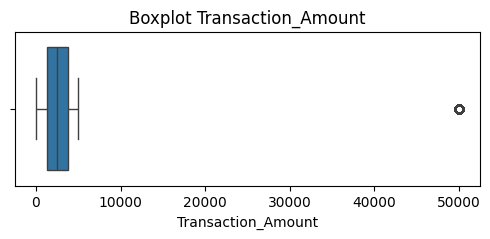

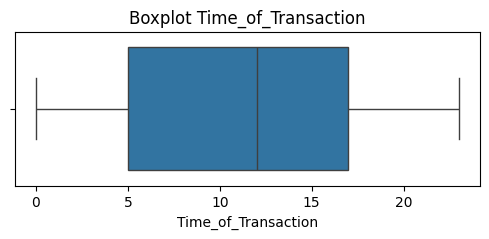

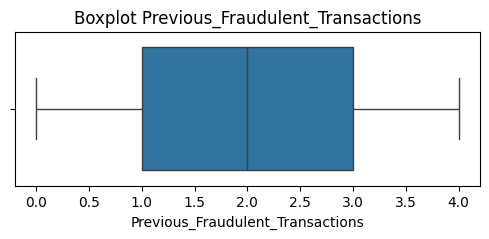

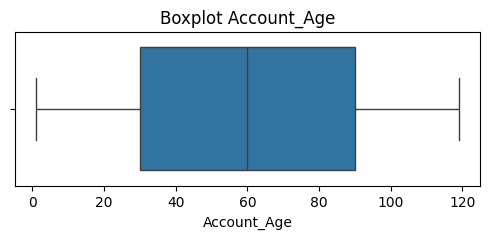

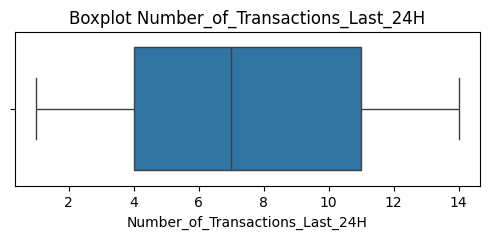

In [126]:
all_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

exclude_cols = ['Fraudulent']
numeric_cols = [col for col in all_cols if col not in exclude_cols]

print(f"Kolom yang dicek outliernya: {numeric_cols}")

for col in numeric_cols:
    plt.figure(figsize=(6, 2))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot {col}')
    plt.show()

# 3. Data Preparation

### 3.1 Drop kolom tidak berguna

In [127]:
df.drop(columns=['Transaction_ID', 'User_ID'], inplace=True)
print(df.shape)

(51000, 10)


In [128]:
df.head()

,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


### 3.2 Mengatasi null value

In [129]:
print(df.isnull().sum())

Transaction_Amount                  2520
Transaction_Type                       0
Time_of_Transaction                 2552
Device_Used                         2473
Location                            2547
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                      2469
Fraudulent                             0
dtype: int64


In [130]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Transaction_Amount                48480 non-null  float64
 1   Transaction_Type                  51000 non-null  object 
 2   Time_of_Transaction               48448 non-null  float64
 3   Device_Used                       48527 non-null  object 
 4   Location                          48453 non-null  object 
 5   Previous_Fraudulent_Transactions  51000 non-null  int64  
 6   Account_Age                       51000 non-null  int64  
 7   Number_of_Transactions_Last_24H   51000 non-null  int64  
 8   Payment_Method                    48531 non-null  object 
 9   Fraudulent                        51000 non-null  int64  
dtypes: float64(2), int64(4), object(4)
memory usage: 3.9+ MB


In [131]:
# Data numerik: isi pakai median
df['Transaction_Amount'].fillna(df['Transaction_Amount'].median(), inplace=True)
df['Time_of_Transaction'].fillna(df['Time_of_Transaction'].median(), inplace=True)

# Data kategorikal: isi pakai modus
df['Device_Used'].fillna(df['Device_Used'].mode()[0], inplace=True)
df['Location'].fillna(df['Location'].mode()[0], inplace=True)
df['Payment_Method'].fillna(df['Payment_Method'].mode()[0], inplace=True)

print(df.isnull().sum())

Transaction_Amount                  0
Transaction_Type                    0
Time_of_Transaction                 0
Device_Used                         0
Location                            0
Previous_Fraudulent_Transactions    0
Account_Age                         0
Number_of_Transactions_Last_24H     0
Payment_Method                      0
Fraudulent                          0
dtype: int64


### 3.3 Mengatasi outlier

In [132]:
df_non_fraud = df[df['Fraudulent'] == 0]

all_cols = df_non_fraud.select_dtypes(include=['int64', 'float64']).columns.tolist()

exclude_cols = ['Fraudulent']
numeric_cols = [col for col in all_cols if col not in exclude_cols]

print(f"Kolom yang dicek outliernya (Non-Fraud): {numeric_cols}")

Kolom yang dicek outliernya (Non-Fraud): ['Transaction_Amount', 'Time_of_Transaction', 'Previous_Fraudulent_Transactions', 'Account_Age', 'Number_of_Transactions_Last_24H']


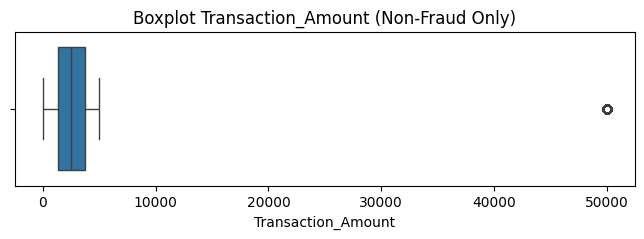

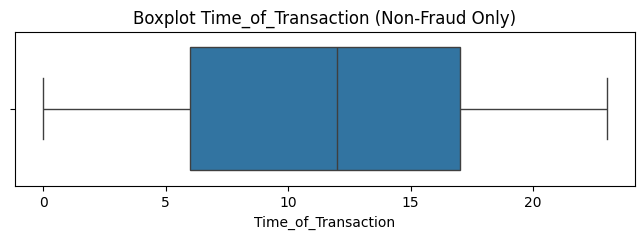

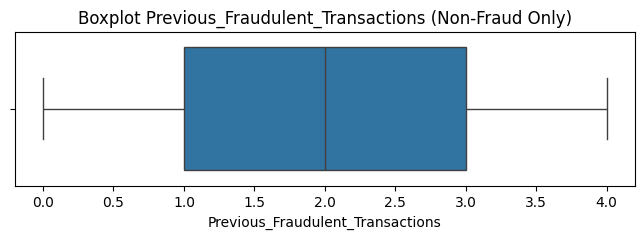

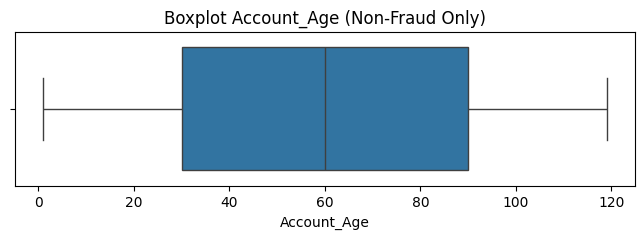

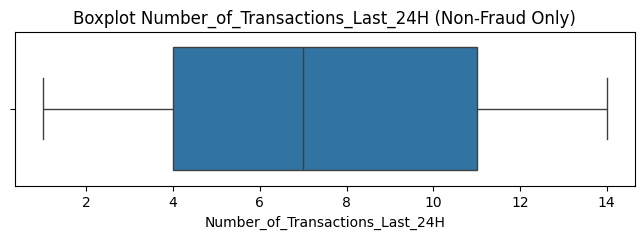

In [133]:
for col in numeric_cols:
    plt.figure(figsize=(8, 2))
    sns.boxplot(x=df_non_fraud[col])
    plt.title(f'Boxplot {col} (Non-Fraud Only)')
    plt.show()

In [134]:
all_outlier = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    interquartile = Q3 - Q1
    lower = Q1 - 1.5 * interquartile
    upper = Q3 + 1.5 * interquartile

    outlier = df[(df['Fraudulent'] == 0) & ((df[col] < lower) | (df[col] > upper))].index.tolist()
    all_outlier.extend(outlier)
    print()
    if len(outlier) > 0:
        print(f"{col} (Non-Fraud):")
        print(f"Jumlah outlier: {len(outlier)}")
        print(f"Index outlier : {outlier}")
    else:
        print(f"{col}: Tidak ada outlier")


Transaction_Amount (Non-Fraud):
Jumlah outlier: 476
Index outlier : [166, 236, 245, 298, 317, 326, 406, 421, 504, 561, 773, 790, 957, 1039, 1282, 1553, 1574, 1625, 1645, 1840, 1977, 2180, 2499, 2615, 2643, 2691, 2708, 2762, 2816, 2861, 2939, 2974, 2980, 3032, 3042, 3103, 3111, 3897, 3914, 4053, 4142, 4149, 4238, 4395, 4421, 4537, 4629, 4788, 4815, 4822, 5076, 5276, 5283, 5370, 5520, 5589, 5644, 5684, 6005, 6081, 6146, 6331, 6383, 6388, 6409, 6578, 6587, 6660, 6839, 6883, 6915, 7348, 7363, 7364, 7430, 7502, 7508, 7539, 7751, 7755, 7807, 8199, 8330, 8345, 8364, 8426, 8454, 8514, 8546, 8553, 8588, 9087, 9118, 9177, 9366, 9733, 9970, 10058, 10195, 10422, 10654, 10754, 10872, 11031, 11050, 11133, 11182, 11193, 11313, 11504, 11572, 11725, 11823, 12047, 12141, 12192, 12209, 12327, 12408, 12444, 12507, 12775, 12799, 12938, 12943, 12979, 12995, 13045, 13057, 13181, 13182, 13203, 13262, 13365, 13509, 13581, 13608, 13771, 13872, 13961, 14104, 14115, 14146, 14364, 14407, 14431, 14514, 14646, 1481

In [135]:
unique_outliers = list(set(all_outlier))
df.drop(index=unique_outliers, inplace=True)
df.shape

(50524, 10)

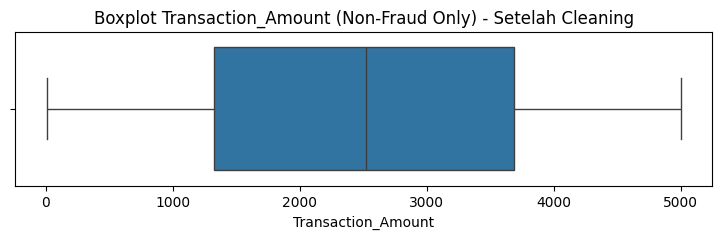

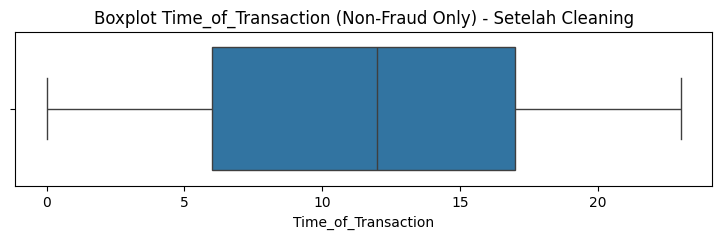

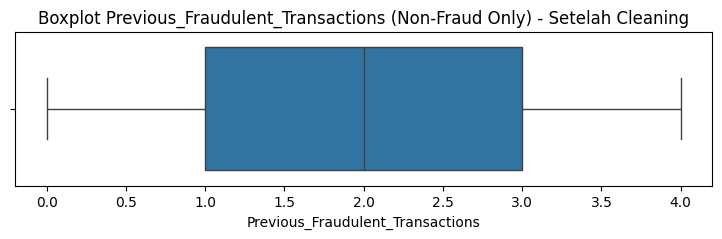

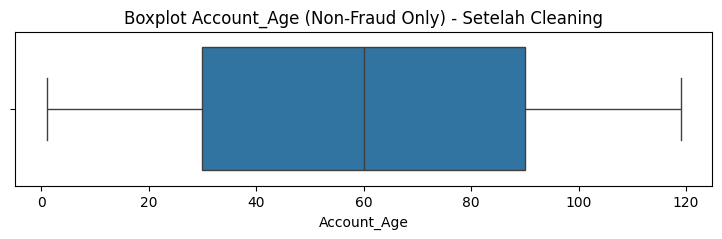

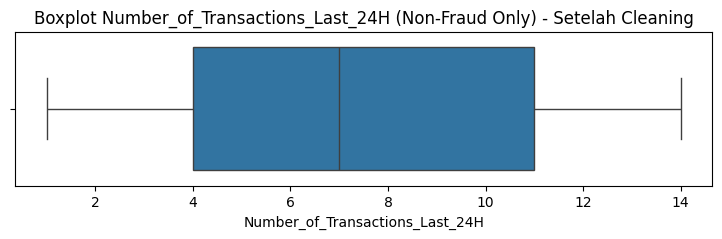

In [136]:
df_non_fraud = df[df['Fraudulent'] == 0]

for col in numeric_cols:
    plt.figure(figsize=(9, 2))
    sns.boxplot(x=df_non_fraud[col])
    plt.title(f'Boxplot {col} (Non-Fraud Only) - Setelah Cleaning')
    plt.show()

In [137]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50524 entries, 0 to 50999
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Transaction_Amount                50524 non-null  float64
 1   Transaction_Type                  50524 non-null  object 
 2   Time_of_Transaction               50524 non-null  float64
 3   Device_Used                       50524 non-null  object 
 4   Location                          50524 non-null  object 
 5   Previous_Fraudulent_Transactions  50524 non-null  int64  
 6   Account_Age                       50524 non-null  int64  
 7   Number_of_Transactions_Last_24H   50524 non-null  int64  
 8   Payment_Method                    50524 non-null  object 
 9   Fraudulent                        50524 non-null  int64  
dtypes: float64(2), int64(4), object(4)
memory usage: 4.2+ MB


### 3.4 Encoding (One-Hot Encoding)

In [138]:
kategorikal_cols = df.select_dtypes(include=['object']).columns.tolist()
df = pd.get_dummies(df, columns=kategorikal_cols, drop_first=True)

x = df.drop('Fraudulent', axis=1)
y = df['Fraudulent']

### 3.5 Train-test split

In [139]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print(f"x_train: {x_train.shape}, x_test: {x_test.shape}")

x_train: (40419, 23), x_test: (10105, 23)


### 3.6 Scaling (StandardScaler)

In [140]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

x_train = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test = pd.DataFrame(x_test_scaled, columns=x_test.columns)

# 4. Modelling

In [141]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score

### 4.1 Random Forest Classsifier

In [142]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
      max_depth=10,
      min_samples_split=5,
      min_samples_leaf=2,
      class_weight='balanced',
      random_state=42
    )

k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cross_validation_score = cross_val_score(rf, x_train, y_train, cv=k_fold, scoring='f1')
print(f"F1-Score per fold: {cross_validation_score}")
print(f"Mean F1-score: {cross_validation_score.mean():.4f}")
print()

rf.fit(x_train, y_train)

print("Training Model Random Forest selesai")

F1-Score per fold: [0.07888041 0.06420546 0.06382979 0.08398134 0.07106599]
Mean F1-score: 0.0724

Training Model Random Forest selesai


### 4.2 Logistic Regression Classifier

In [143]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
      C = 1.0,
      class_weight='balanced',
      random_state=42,
      max_iter=1000)

k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cross_validation_score = cross_val_score(lr, x_train, y_train, cv=k_fold, scoring='f1')
print(f"F1-Score per fold: {cross_validation_score}")
print(f"Mean F1-score: {cross_validation_score.mean():.4f}")
print()

lr.fit(x_train, y_train)

print("Training Model Logistic Regression selesai")

F1-Score per fold: [0.08978175 0.09547366 0.09084249 0.09382093 0.08627064]
Mean F1-score: 0.0912

Training Model Logistic Regression selesai


### 4.3 Decision Tree Classifier

In [144]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
      max_depth=10,
      min_samples_split=5,
      min_samples_leaf=2,
      class_weight='balanced',
      random_state=42
      )

k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cross_validation_score = cross_val_score(dt, x_train, y_train, cv=k_fold, scoring='f1')
print(f"F1-Score per fold: {cross_validation_score}")
print(f"Mean F1-score: {cross_validation_score.mean():.4f}")
print()

dt.fit(x_train, y_train)

print("Training Model Decision Tree selesai")

F1-Score per fold: [0.09036422 0.09378085 0.10055866 0.1024578  0.06589147]
Mean F1-score: 0.0906

Training Model Decision Tree selesai


### 4.4 Naive Bayes Classifier

In [145]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cross_validation_score = cross_val_score(nb, x_train, y_train, cv=k_fold, scoring='f1')
print(f"F1-Score per fold: {cross_validation_score}")
print(f"Mean F1-score: {cross_validation_score.mean():.4f}")
print()

nb.fit(x_train, y_train)

print("Training Model Naive Bayes selesai")

F1-Score per fold: [0.03431373 0.03902439 0.01970443 0.03902439 0.00992556]
Mean F1-score: 0.0284

Training Model Naive Bayes selesai


# 5. Evaluation

### 5.1 Hasil Metrik Masing-Masing Model

##### 5.1.1 Hasil Metrik Model Random Forest Classifier

Random Forest
Accuracy : 0.9172
Precision: 0.0738
Recall   : 0.0578
F1-Score : 0.0648

Classification Report :
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      9603
           1       0.07      0.06      0.06       502

    accuracy                           0.92     10105
   macro avg       0.51      0.51      0.51     10105
weighted avg       0.91      0.92      0.91     10105


Confusion Matrix :
[[9239  364]
 [ 473   29]]


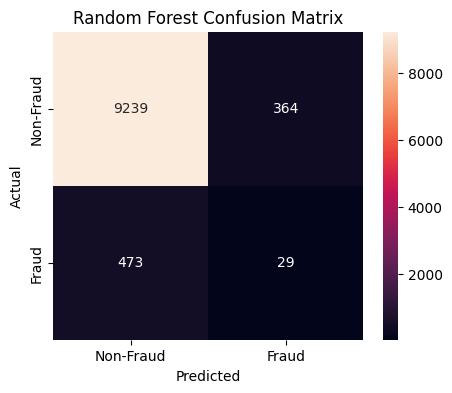

In [146]:
y_pred_rf = rf.predict(x_test)

rf_acc = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf)
rf_rec = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("Random Forest")
print(f"Accuracy : {rf_acc:.4f}")
print(f"Precision: {rf_prec:.4f}")
print(f"Recall   : {rf_rec:.4f}")
print(f"F1-Score : {rf_f1:.4f}")
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_rf))

print()
print("Confusion Matrix :")
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)
plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt='d', xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
plt.title('Random Forest Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

##### 5.1.2 Hasil Metrik Model Logistic Regression Classifier

Logistic Regression
Accuracy : 0.5461
Precision: 0.0470
Recall   : 0.4223
F1-Score : 0.0846

Classification Report :
              precision    recall  f1-score   support

           0       0.95      0.55      0.70      9603
           1       0.05      0.42      0.08       502

    accuracy                           0.55     10105
   macro avg       0.50      0.49      0.39     10105
weighted avg       0.90      0.55      0.67     10105


Confusion Matrix :
[[5306 4297]
 [ 290  212]]


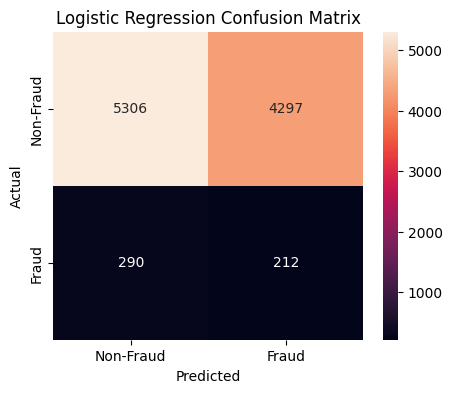

In [147]:
y_pred_lr = lr.predict(x_test)

lr_acc = accuracy_score(y_test, y_pred_lr)
lr_prec = precision_score(y_test, y_pred_lr)
lr_rec = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

print("Logistic Regression")
print(f"Accuracy : {lr_acc:.4f}")
print(f"Precision: {lr_prec:.4f}")
print(f"Recall   : {lr_rec:.4f}")
print(f"F1-Score : {lr_f1:.4f}")
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_lr))

print()
print("Confusion Matrix :")
cm_lr = confusion_matrix(y_test, y_pred_lr)
print(cm_lr)
plt.figure(figsize=(5,4))
sns.heatmap(cm_lr, annot=True, fmt='d', xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
plt.title('Logistic Regression Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

##### 5.1.3 Hasil Metrik Model Decision Tree Classifier

Decision Tree
Accuracy : 0.6195
Precision: 0.0527
Recall   : 0.3924
F1-Score : 0.0929

Classification Report :
              precision    recall  f1-score   support

           0       0.95      0.63      0.76      9603
           1       0.05      0.39      0.09       502

    accuracy                           0.62     10105
   macro avg       0.50      0.51      0.43     10105
weighted avg       0.91      0.62      0.73     10105


Confusion Matrix :
[[6063 3540]
 [ 305  197]]


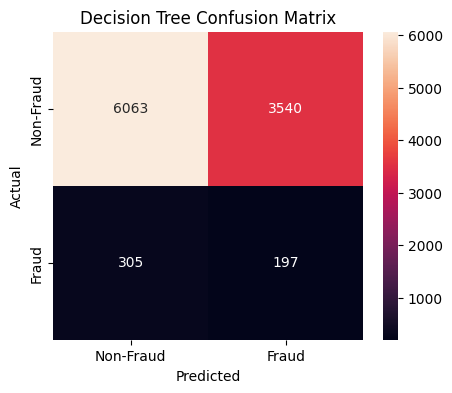

In [148]:
y_pred_dt = dt.predict(x_test)

dt_acc = accuracy_score(y_test, y_pred_dt)
dt_prec = precision_score(y_test, y_pred_dt)
dt_rec = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)

print("Decision Tree")
print(f"Accuracy : {dt_acc:.4f}")
print(f"Precision: {dt_prec:.4f}")
print(f"Recall   : {dt_rec:.4f}")
print(f"F1-Score : {dt_f1:.4f}")
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_dt))

print()
print("Confusion Matrix :")
cm_dt = confusion_matrix(y_test, y_pred_dt)
print(cm_dt)
plt.figure(figsize=(5,4))
sns.heatmap(cm_dt, annot=True, fmt='d', xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
plt.title('Decision Tree Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

##### 5.1.4 Hasil Metrik Model Naive Bayes Classifier

Naive Bayes
Accuracy : 0.9506
Precision: 1.0000
Recall   : 0.0060
F1-Score : 0.0119

Classification Report :
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      9603
           1       1.00      0.01      0.01       502

    accuracy                           0.95     10105
   macro avg       0.98      0.50      0.49     10105
weighted avg       0.95      0.95      0.93     10105


Confusion Matrix :
[[9603    0]
 [ 499    3]]


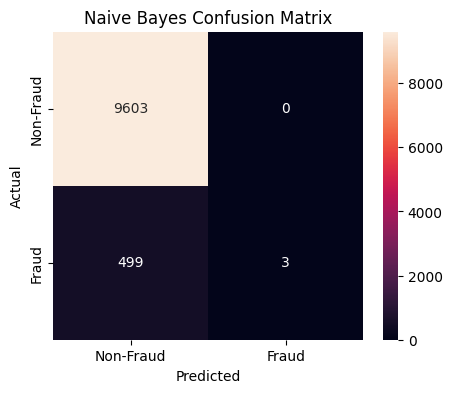

In [149]:
y_pred_nb = nb.predict(x_test)

nb_acc = accuracy_score(y_test, y_pred_nb)
nb_prec = precision_score(y_test, y_pred_nb)
nb_rec = recall_score(y_test, y_pred_nb)
nb_f1 = f1_score(y_test, y_pred_nb)

print("Naive Bayes")
print(f"Accuracy : {nb_acc:.4f}")
print(f"Precision: {nb_prec:.4f}")
print(f"Recall   : {nb_rec:.4f}")
print(f"F1-Score : {nb_f1:.4f}")
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_nb))

print()
print("Confusion Matrix :")
cm_nb = confusion_matrix(y_test, y_pred_nb)
print(cm_nb)
plt.figure(figsize=(5,4))
sns.heatmap(cm_nb, annot=True, fmt='d', xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
plt.title('Naive Bayes Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

### 5.2 Perbandingan Metrik Keempat Model

In [150]:
print("Perbandingan Model")
print()

print(f"Random Forest       : Acc={rf_acc:.4f}, Prec={rf_prec:.4f}, Rec={rf_rec:.4f}, F1={rf_f1:.4f}")
print(f"Logistic Regression : Acc={lr_acc:.4f}, Prec={lr_prec:.4f}, Rec={lr_rec:.4f}, F1={lr_f1:.4f}")
print(f"Decision Tree       : Acc={dt_acc:.4f}, Prec={dt_prec:.4f}, Rec={dt_rec:.4f}, F1={dt_f1:.4f}")
print(f"Naive Bayes         : Acc={nb_acc:.4f}, Prec={nb_prec:.4f}, Rec={nb_rec:.4f}, F1={nb_f1:.4f}")

Perbandingan Model

Random Forest       : Acc=0.9172, Prec=0.0738, Rec=0.0578, F1=0.0648
Logistic Regression : Acc=0.5461, Prec=0.0470, Rec=0.4223, F1=0.0846
Decision Tree       : Acc=0.6195, Prec=0.0527, Rec=0.3924, F1=0.0929
Naive Bayes         : Acc=0.9506, Prec=1.0000, Rec=0.0060, F1=0.0119


### 5.3 Visualisasi Perbandingan

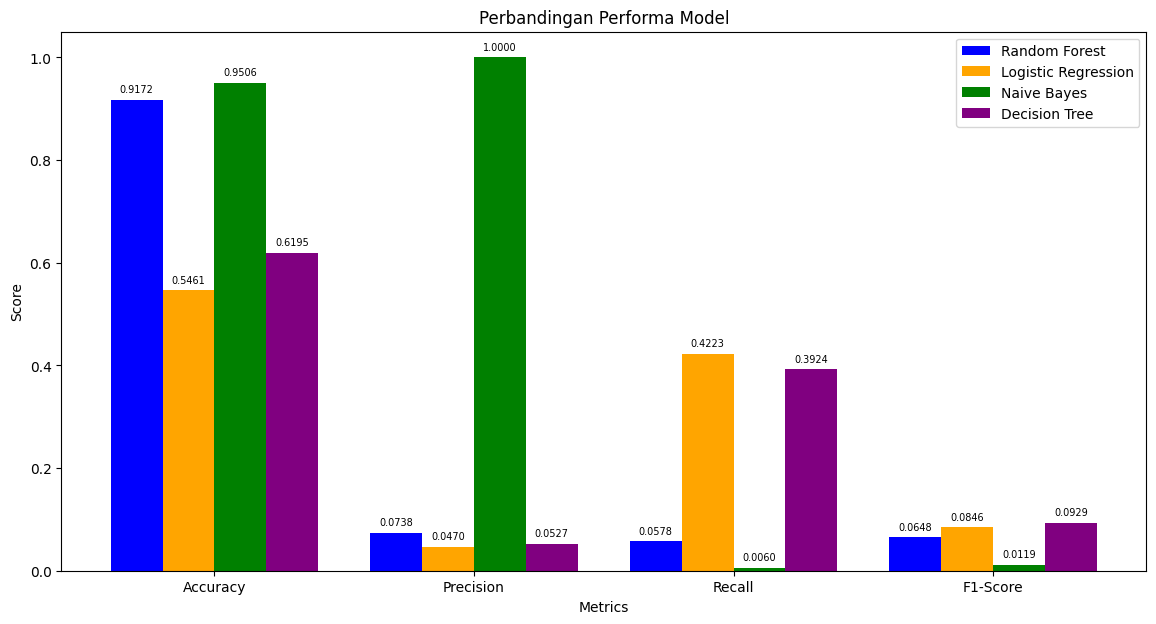

In [151]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

rf_scores = [rf_acc, rf_prec, rf_rec, rf_f1]
lr_scores = [lr_acc, lr_prec, lr_rec, lr_f1]
nb_scores = [nb_acc, nb_prec, nb_rec, nb_f1]
dt_scores = [dt_acc, dt_prec, dt_rec, dt_f1]

x = range(len(metrics))
width = 0.2

plt.figure(figsize=(14, 7))

bar1 = plt.bar([i - width*1.5 for i in x], rf_scores, width, label='Random Forest', color='blue')
bar2 = plt.bar([i - width/2 for i in x], lr_scores, width, label='Logistic Regression', color='orange')
bar3 = plt.bar([i + width/2 for i in x], nb_scores, width, label='Naive Bayes', color='green')
bar4 = plt.bar([i + width*1.5 for i in x], dt_scores, width, label='Decision Tree', color='purple')

for bars in [bar1, bar2, bar3, bar4]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            plt.text(bar.get_x() + bar.get_width()/2., height + 0.01, f'{height:.4f}', ha='center', va='bottom', fontsize=7)

plt.xlabel('Metrics')
plt.ylabel('Score')
plt.title('Perbandingan Performa Model')
plt.xticks(x, metrics)
plt.legend()
plt.show()